# Introduction - Model Selection
In this section, we aim to identify the most suitable machine learning model for predicting housing prices in Melbourne.
We use the cleaned and preprocessed dataset and the previously developed feature engineering and preprocessing pipeline (`melbourne_price.pipeline.build_base_pipeline`).
Multiple regression models are tested with cross-validation and hyperparameter tuning.
The final model is selected based on performance metrics and model interpretability.

> **Key findings**
> - Five models tuned with `GridSearchCV` (5-fold CV, preprocessing refit inside every fold to avoid leakage).
> - Mean CV R² (log price): **Gradient Boosting 0.778**, Random Forest 0.770, Lasso 0.666, Linear Regression 0.666, KNN 0.477.
> - Selected **Gradient Boosting** (`learning_rate=0.05`, `max_depth=7`, `min_samples_split=5`, `n_estimators=150`).


In [1]:
from statistics import variance

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from melbourne_price.pipeline import build_base_pipeline

## 1. Load dataset and pipeline

In [2]:
full_pipeline = build_base_pipeline()
# Load cleaned dataset
df = pd.read_csv("../data/processed/melbourne_housing_cleaned_featEngr.csv")
df.head()

,Suburb,Type,Method,SellerG,Distance,Bedroom,Bathroom,Car,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,Price,Log_Landsize,Log_BuildingArea,PropertyAge,Log_TotalArea,Is_CBD
0,Northcote,u,S,McGrath,5.3,3.0,1.0,2.0,Darebin City Council,-37.806498,144.992667,Northern Metropolitan,11364.0,673000.0,6.246107,4.317488,47.0,6.380123,0
1,Bentleigh East,h,S,Jellis,13.8,3.0,1.0,2.0,Glen Eira City Council,-37.912970,145.073500,Southern Metropolitan,10969.0,1372500.0,6.246107,5.003946,57.0,6.498282,0
2,Reservoir,h,S,Stockdale,12.0,3.0,1.0,1.0,Darebin City Council,-37.729240,145.029810,Northern Metropolitan,21650.0,612500.0,5.141664,4.859812,67.0,5.700444,0
3,Jacana,h,S,YPA,14.5,3.0,1.0,2.0,Hume City Council,-37.806498,144.992667,Northern Metropolitan,851.0,515000.0,6.246107,5.003946,57.0,6.498282,0
4,Prahran,h,S,Marshall,4.5,2.0,2.0,2.0,Stonnington City Council,-37.847600,144.989200,Southern Metropolitan,7717.0,2180000.0,5.476464,5.036953,127.0,5.971262,1


In [3]:
X = df.drop(columns=["Price"])
y = np.log1p(df["Price"])  # target on log scale

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

## 2. Define Models and Parameter Grids

Compare several regression models:
- Linear Regression (baseline)
- Lasso Regression
- Random Forest Regressor
- Gradient Boosting Regressor
- KNN 

Attach them to our pipeline dynamically.

In [4]:
# ============================================
# 2. DEFINE MODELS AND PARAMETER GRIDS
# ============================================

models = {
    "LinearRegression": LinearRegression(),
    "Lasso": Lasso(max_iter=5000),
    "RandomForest": RandomForestRegressor(random_state=0, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=0),
    "KNN": KNeighborsRegressor(n_neighbors=5, weights='distance'),
}

param_grids = {
    "LinearRegression": {},  # no major hyperparameters
    "Lasso": {"model__alpha": [0.0001, 0.001, 0.01, 0.1, 1]},# Controls regularization strength
    "RandomForest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5]
    },
    "GradientBoosting": {
        "model__n_estimators": [100, 150],
        "model__learning_rate": [0.01, 0.05],
        "model__max_depth": [3,5,7],
        "model__min_samples_split": [2,5]
    }, 
    "KNN": {
        "model__n_neighbors": list(range(3, 51, 2)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]  # Manhattan vs Euclidean
    }
}

cv = KFold(n_splits=5, shuffle=True, random_state=0)
results = []

### Preprocessing *inside* cross‑validation (cloning the base pipeline)

For **every candidate model**, we **clone** the same base preprocessing pipeline and **swap only the final estimator**.
This guarantees that **all preprocessing (imputation, encoding, scaling, feature engineering, etc.) is refit inside each CV fold**, avoiding data leakage and making scores comparable across models.

Concretely, we:

1. Build the base pipeline (`melbourne_price.pipeline.build_base_pipeline()`).
2. For each model, **`sklearn.base.clone`** the base pipeline and **replace its final step** with the candidate estimator.
3. Run `GridSearchCV` on the full pipeline so preprocessing is included in the CV loop.

In [5]:
from sklearn.feature_selection import RFECV

# ============================================
# 3. MODEL SELECTION & GRID SEARCH
# ============================================

for name, model in models.items():
    print(f"\n=== Tuning {name} ===")
    pipe = build_base_pipeline()
    pipe.set_params(model=model)
    pipe.set_params(rfecv="passthrough")  # disable feature selection for fair comparison
    
    if model in ["RandomForest", "GradientBoosting"]:
        pipe.set_params(variance="passthrough")#GradientBoosting and RandomForest internally use feature importance to select the best features

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        scoring="r2",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )
    grid.fit(X_train, y_train)

    results.append({
        "Model": name,
        "Best_Params": grid.best_params_,
        "Mean_R2": grid.best_score_,
        "Best_Estimator": grid.best_estimator_,
        "CV_Std": np.std(grid.cv_results_["mean_test_score"], ddof=0)
    })

results_df = pd.DataFrame(results).sort_values("Mean_R2", ascending=False).reset_index(drop=True)
print("\n=== Cross-Validated Results ===")
display(results_df[["Model", "Mean_R2", "CV_Std", "Best_Params"]])


=== Tuning LinearRegression ===
Fitting 5 folds for each of 1 candidates, totalling 5 fits



=== Tuning Lasso ===
Fitting 5 folds for each of 5 candidates, totalling 25 fits



=== Tuning RandomForest ===
Fitting 5 folds for each of 12 candidates, totalling 60 fits



=== Tuning GradientBoosting ===
Fitting 5 folds for each of 24 candidates, totalling 120 fits



=== Tuning KNN ===
Fitting 5 folds for each of 96 candidates, totalling 480 fits



=== Cross-Validated Results ===


,Model,Mean_R2,CV_Std,Best_Params
0,GradientBoosting,0.778368,0.090363,"{'model__learning_rate': 0.05, 'model__max_dep..."
1,RandomForest,0.769817,0.003076,"{'model__max_depth': None, 'model__min_samples..."
2,Lasso,0.665680,0.258785,{'model__alpha': 0.0001}
3,LinearRegression,0.665603,0.000000,{}
4,KNN,0.476643,0.073047,"{'model__n_neighbors': 9, 'model__p': 1, 'mode..."


In [6]:
results_df["Best_Params"][0]

{'model__learning_rate': 0.05,
 'model__max_depth': 7,
 'model__min_samples_split': 5,
 'model__n_estimators': 150}

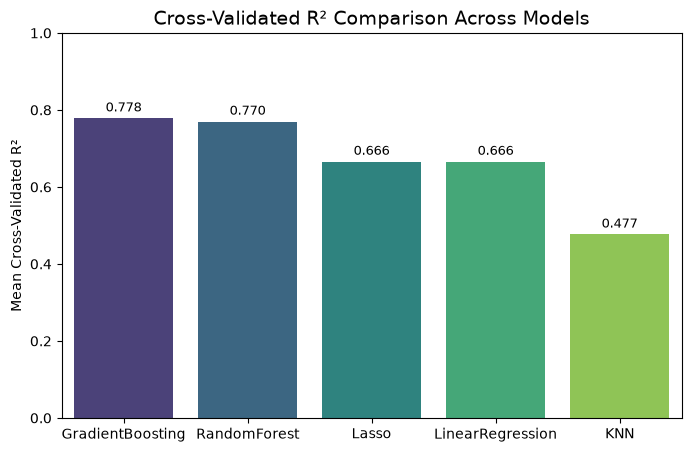

In [7]:
# ============================================
# 4. VISUALIZE MODEL PERFORMANCE
# ============================================

plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x="Model", y="Mean_R2", palette="viridis", hue="Model",
            order=results_df.sort_values("Mean_R2", ascending=False)["Model"])
plt.title("Cross-Validated R² Comparison Across Models", fontsize=14)
plt.ylabel("Mean Cross-Validated R²")
plt.xlabel("")
plt.ylim(0, 1)
for index, row in results_df.iterrows():
    plt.text(index, row["Mean_R2"] + 0.01, f"{row['Mean_R2']:.3f}", ha='center', va='bottom', fontsize=9)
plt.savefig("../docs/images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Final Model Rationale — Gradient Boosting Regressor
The Gradient Boosting Regressor was selected as the final model because it achieved the highest mean cross-validated R² (0.778) while maintaining moderate variability across folds (CV_Std ≈ 0.09) indicating strong and consistent predictive performance.

**Why Gradient Boosting?**
- Bias–Variance Trade-off:
Gradient Boosting achieves a good balance it captures nonlinear relationships (lower bias) without excessive overfitting (controlled variance), as seen in the low-to-moderate CV spread.
- Stability Across Folds:
The model’s R² scores are relatively stable compared to Lasso (high variance) and only slightly more variable than Random Forest, suggesting robust generalization.
- Performance:
Its mean R² exceeds that of Random Forest by ~0.009, a meaningful margin in this context, indicating slightly better fit while maintaining comparable reliability.
- Interpretability and Efficiency:
While not as interpretable as linear models, Gradient Boosting provides feature importances and partial dependence plots that still allow insight into drivers of price.

**Best Hyperparameters:**
learning_rate = 0.05, max_depth = 7, min_samples_split = 5, n_estimators = 150
These settings represent a moderately deep ensemble with conservative learning, promoting both stability and accuracy.

## Conclusion:
Gradient Boosting provides the best overall generalization and balanced bias–variance profile, making it the preferred final model for deployment.